In [2]:
%pip install seaborn


In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [4]:
df = pd.read_csv("uber.csv")
print(df.columns)
df = df.drop(["Unnamed: 0", "key"], axis=1)
df = df.dropna()

Index(['Unnamed: 0', 'key', 'fare_amount', 'pickup_datetime',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'passenger_count'],
      dtype='str')


In [5]:
df ["distance"] = np.sqrt((df['dropoff_longitude'] - df['pickup_longitude']) **2 +
(df['dropoff_latitude'] - df['pickup_latitude']) **2)

In [6]:
df = df[(df["fare_amount"] > 0) & (df["distance"] > 0)]
df = df.sample(50000, random_state = 42)

In [7]:
cols = ['fare_amount', 'distance']
Q1 = df[cols].quantile(0.25)
Q3 = df[cols].quantile(0.75)
IQR = Q3 - Q1
df = df[~((df[cols] < Q1 - 1.5 * IQR) | (df[cols] > Q3 + 1.5 * IQR)).any(axis=1)]

In [8]:
print(df[['fare_amount', 'distance', 'passenger_count']].corr())

                 fare_amount  distance  passenger_count
fare_amount         1.000000  0.819921         0.013661
distance            0.819921  1.000000         0.000515
passenger_count     0.013661  0.000515         1.000000


In [9]:
X = df[['distance', 'passenger_count']]
y = df['fare_amount']
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42)

In [10]:
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

In [11]:
rf = RandomForestRegressor(n_estimators=20, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

In [12]:
print("Linear  R2:", r2_score(y_test, pred_lr))
print("Linear  RMSE:", np.sqrt(mean_squared_error(y_test, pred_lr)))
print("Linear  MAE:", mean_absolute_error(y_test, pred_lr))

print("Forest  R2:", r2_score(y_test, pred_rf))
print("Forest  RMSE:", np.sqrt(mean_squared_error(y_test, pred_rf)))
print("Forest  MAE:", mean_absolute_error(y_test, pred_rf))

Linear  R2: 0.6713672544844517
Linear  RMSE: 2.286974444611775
Linear  MAE: 1.6343627184664673
Forest  R2: 0.546349135547317
Forest  RMSE: 2.68699442612256
Forest  MAE: 1.9373099206349207


                 fare_amount  distance  passenger_count
fare_amount         1.000000  0.819921         0.013661
distance            0.819921  1.000000         0.000515
passenger_count     0.013661  0.000515         1.000000


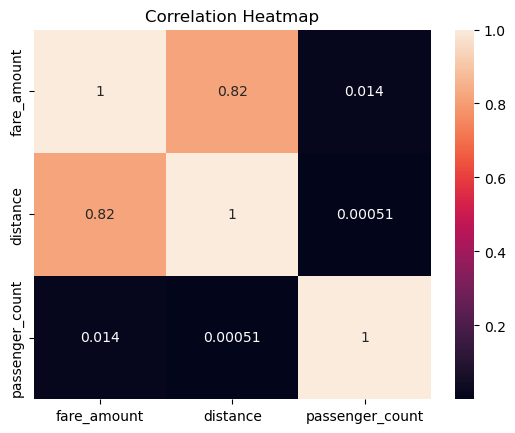

In [13]:
corr = df[['fare_amount', 'distance', 'passenger_count']].corr()
print(corr)

sns.heatmap(corr, annot=True)
plt.title("Correlation Heatmap")
plt.show()